---
title: "Boltzmann Statistics and the Partition Function — Level 2"
short_title: "06 Boltzmann Statistics"
numbering:
  heading_2: true
  equation: true
---

# Boltzmann Statistics and the Partition Function

:::{seealso} Math for this topic
- [T-M2: Gaussian, Gamma and quantum-statistics integrals](../math/02-gaussian-gamma-integrals.ipynb)
- [T-M1: Counting, probability and Stirling's approximation](../math/01-counting-probability-stirling.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Schroeder, ch. 6** | **Boltzmann factor, the partition function, rotational and vibrational heat capacities** |
| 3 | Pathria, ch. 3 | Canonical ensemble, fluctuations, equivalence of ensembles |

The new skill at this level: computing everything about a system at fixed temperature from one sum over its states

Math for this topic: T-M2 (Gaussian integrals), T-M1 (probability) and mechanics M1 (Taylor series).
:::

Workbook example ladder: the two-level system → rotational and vibrational modes of a diatomic molecule → energy fluctuations and their link to heat capacity. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Quantum Statistics: Fermions and Bosons](07-quantum-statistics.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **The Boltzmann Factor**

   Two levels are separated by 0.10 eV. At 300 K, find the population ratio upper/lower. Then redo it with the upper level threefold degenerate.

2. **What the Partition Function Gives You**

   For $Z = 1 + e^{-\beta\epsilon}$, find $\bar E$ and $F$.

3. **The Two-Level System**

   For the system in problem 2, find $\bar E$ and $C$ in the limits $kT \ll \epsilon$ and $kT \gg \epsilon$. Why is there a peak in $C$ between them?

4. **Equipartition, Proved**

   (a) For a single degree of freedom with $E = cq^2$, show from $Z$ that $\bar E = \tfrac12kT$.

   (b) What is $\bar E$ if instead $E = c|q|$?

5. **Diatomic Molecules: Rotation and Vibration**

   N₂ has a vibrational quantum $hf \approx 0.29$ eV. At 300 K, what fraction of molecules is in the first excited vibrational state? What does that say about its heat capacity?

6. **The Ideal Gas from $Z$**

   (a) Compute the quantum length $\ell_Q = h/\sqrt{2\pi mkT}$ for helium at 300 K, and compare $v_Q = \ell_Q^3$ with $V/N$ at 1 atm. Is Boltzmann statistics valid?

   (b) Estimate $\sigma_E/\bar E$ for $10^{23}$ monatomic gas atoms, using $\sigma_E^2 = kT^2C$.

:::{dropdown} Answers
1. $e^{-0.10/0.02585} \approx 0.021$. With threefold degeneracy, $\approx 0.063$.

2. $\bar E = -\partial_\beta\ln Z = \dfrac{\epsilon}{e^{\beta\epsilon} + 1}$, and $F = -kT\ln\left(1 + e^{-\epsilon/kT}\right)$.

3. For $kT \ll \epsilon$, $\bar E \to 0$ and $C \to 0$ exponentially. For $kT \gg \epsilon$, $\bar E \to \epsilon/2$ and $C \to 0$ as $1/T^2$. In between, $\bar E$ changes fastest, giving the Schottky peak.

4. (a) $Z \propto \int e^{-\beta cq^2}dq \propto \beta^{-1/2}$, so $\bar E = \dfrac{1}{2\beta} = \tfrac12kT$.

   (b) $Z \propto \beta^{-1}$, so $\bar E = kT$.

5. About $e^{-0.29/0.0259} \approx 1.3\times10^{-5}$. Vibration is frozen out and contributes nothing to $C$.

6. (a) $\ell_Q \approx 5\times10^{-11}$ m, so $v_Q \approx 1.3\times10^{-31}\ \text{m}^3$. Since $V/N = kT/P \approx 4\times10^{-26}\ \text{m}^3$, which is much larger, Boltzmann statistics is valid.

   (b) $\sigma_E/\bar E = 1/\sqrt{1.5N} \approx 3\times10^{-12}$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Boltzmann Factor

Topic 3 handled isolated systems, where all microstates are equally likely. Most systems instead sit in contact with surroundings at a fixed temperature. Take a small system (one atom, one molecule) in contact with a huge reservoir at temperature $T$.

:::{prf:theorem} Boltzmann distribution
:label: thm-boltzmann

The probability that the small system is in a particular microstate $s$ with energy $E(s)$ is

$$
P(s) = \frac{e^{-E(s)/kT}}{Z},\qquad Z = \sum_se^{-E(s)/kT} .
$$ (eq-boltzmann)

$Z$ is the **partition function**.
:::

:::{prf:proof}
:class: dropdown

With the system in state $s$, the reservoir has energy $U_0 - E(s)$, and every reservoir microstate is equally likely. So $P(s)\propto\Omega_R(U_0 - E(s)) = e^{S_R(U_0 - E(s))/k}$. The system's energy is tiny on the reservoir's scale, so Taylor-expand $S_R$ to first order:

$$
S_R(U_0 - E) \approx S_R(U_0) - E\frac{\partial S_R}{\partial U} = S_R(U_0) - \frac ET .
$$

The first term is the same for every $s$, leaving $P(s)\propto e^{-E(s)/kT}$. Normalizing gives $Z$. (T-M3 derives the same result by maximizing entropy with a Lagrange multiplier.)
:::

Two points that trip people up. First, $P(s)$ is the probability of one *state*. If several states share an energy (degeneracy $g$), the probability of that *energy* is $g\,e^{-E/kT}/Z$. Second, the Boltzmann factor favors low energy only state by state; when high-energy states are numerous (like fast speeds in the Maxwell distribution), they can still dominate.

## What the Partition Function Gives You

Write $\beta = 1/kT$. Every average follows from derivatives of $\ln Z$:

$$
\bar E = -\frac{\partial\ln Z}{\partial\beta},\qquad
F = -kT\ln Z,\qquad
S = -\frac{\partial F}{\partial T},\qquad
C = \frac{\partial\bar E}{\partial T} .
$$ (eq-Z-derivatives)

The first is one line: $-\partial_\beta\ln Z = \sum_sE(s)e^{-\beta E(s)}/Z = \bar E$. The second needs the entropy of the distribution (Pathria proves it; Schroeder motivates it). Once you know the states and their energies, $Z$ is a sum, and thermodynamics is differentiation.

For independent subsystems, $Z$ multiplies: a molecule with translation, rotation and vibration that do not interact has $Z_1 = Z_{\text{tr}}Z_{\text{rot}}Z_{\text{vib}}$, so $\ln Z$ and every property add.

## The Two-Level System

The simplest nontrivial case: two states with energies $0$ and $\epsilon$ (a spin in a magnetic field, a defect that can sit in two positions).

$$
Z = 1 + e^{-\beta\epsilon},\qquad
\bar E = \frac{\epsilon}{e^{\beta\epsilon} + 1},\qquad
C = k\frac{(\beta\epsilon)^2e^{\beta\epsilon}}{(e^{\beta\epsilon} + 1)^2} .
$$ (eq-two-level)

In [2]:
beta, eps, k, T = sp.symbols("beta epsilon k T", positive=True)
Z = 1 + sp.exp(-beta * eps)
E = sp.simplify(-sp.diff(sp.log(Z), beta))
C = sp.simplify(sp.diff(E.subs(beta, 1 / (k * T)), T))
display(Math(r"\bar E = " + sp.latex(E)))
display(Math(r"C = " + sp.latex(C)))
# Fluctuations: variance of E equals k T^2 C
var = sp.simplify(sp.diff(Z, beta, 2) / Z - E**2)          # <E^2> - <E>^2
kT2C = sp.simplify(-sp.diff(E, beta))                        # k T^2 dE/dT = -dE/dbeta
display(Math(r"\sigma_E^2 = " + sp.latex(var) + r",\qquad \sigma_E^2 - kT^2C = " + sp.latex(sp.simplify((var - kT2C).rewrite(sp.exp)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

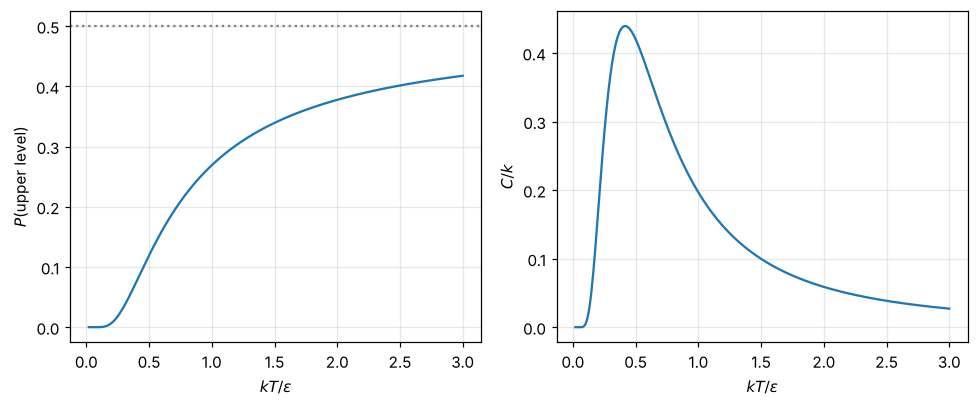

In [3]:
#| label: fig-schottky
#| caption: "Two-level system. Left, occupation of the upper level rises from 0 toward ½ (never above, at positive temperature). Right, the heat capacity has a peak near kT ≈ 0.42ε, the Schottky anomaly, which shows up in real materials as a bump in C at low temperature."
t = np.linspace(0.02, 3, 400); x = 1 / t
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
a1.plot(t, 1 / (np.exp(x) + 1)); a1.axhline(0.5, ls=":", color="gray")
a1.set_xlabel("$kT/\\epsilon$"); a1.set_ylabel("$P$(upper level)")
a2.plot(t, x**2 * np.exp(x) / (np.exp(x) + 1)**2)
a2.set_xlabel("$kT/\\epsilon$"); a2.set_ylabel("$C/k$")
plt.tight_layout(); plt.show()

The heat capacity is small at low $T$ (too cold to reach the upper level) and at high $T$ (both levels equally full, no more energy can go in). A system with a *bounded* energy spectrum can never absorb energy forever, unlike a gas.

## Equipartition, Proved

For a classical degree of freedom with energy $E = cq^2$, replace the sum over states by an integral over $q$ (the spacing of states becomes negligible when $kT$ is large compared with it):

$$
Z\propto\int_{-\infty}^\infty e^{-\beta cq^2}\,dq = \sqrt{\frac{\pi}{\beta c}}\quad\Rightarrow\quad \bar E = -\frac{\partial}{\partial\beta}\left(-\tfrac12\ln\beta + \text{const}\right) = \frac{1}{2\beta} = \frac12kT .
$$

The constant $c$ drops out: this is why every quadratic term gets the same share (topic 1). The proof also shows when it fails: when the levels are spaced by more than $kT$, the integral is a poor approximation of the sum.

## Diatomic Molecules: Rotation and Vibration

**Rotation.** A rigid rotor has levels $E_j = j(j+1)\epsilon$ with degeneracy $2j + 1$, where $\epsilon = \hbar^2/2I$ is tiny for most molecules (CO: $\epsilon/k = 2.8$ K). For $kT\gg\epsilon$ the sum becomes an integral:

$$
Z_{\text{rot}} = \sum_j(2j+1)e^{-j(j+1)\epsilon/kT}\approx\int_0^\infty(2j+1)e^{-j(j+1)\epsilon/kT}dj = \frac{kT}{\epsilon} ,
$$ (eq-z-rot)

giving $\bar E_{\text{rot}} = kT$: two quadratic rotational degrees of freedom, as equipartition says. (For a molecule with identical atoms, like N₂, only half the $j$ values are allowed and $Z_{\text{rot}} = kT/2\epsilon$, which leaves $\bar E$ unchanged.)

**Vibration.** A harmonic oscillator has levels $nhf$ (dropping the zero-point energy), and $Z$ is a geometric series:

$$
Z_{\text{vib}} = \sum_{n=0}^\infty e^{-nhf/kT} = \frac{1}{1 - e^{-hf/kT}},\qquad \bar E_{\text{vib}} = \frac{hf}{e^{hf/kT} - 1} .
$$ (eq-z-vib)

At high $T$, $\bar E_{\text{vib}}\to kT$; at low $T$ it vanishes exponentially. This is the Einstein-solid result of topic 3, now from one line of algebra. For N₂, $hf/k = 3390$ K, so at room temperature vibration is frozen and $C_V = \tfrac52Nk$. Topic 1's heat-capacity staircase is exactly $C_{\text{tr}} + C_{\text{rot}} + C_{\text{vib}}$ from these partition functions.

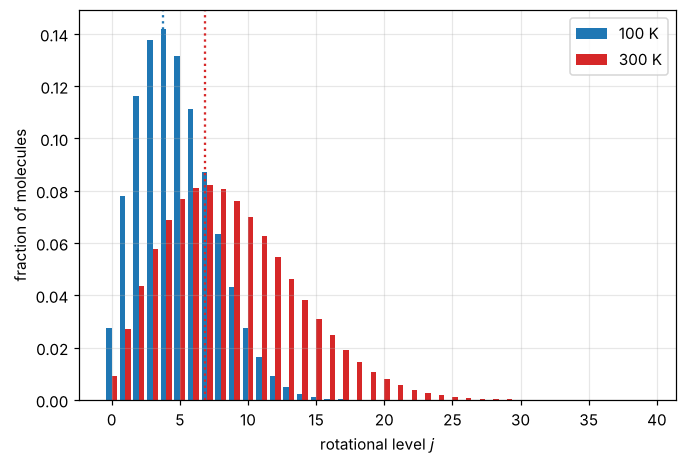

In [4]:
#| label: fig-co-rotational
#| caption: "Populations of the rotational levels j of CO (ε/k = 2.77 K) at 100 K and 300 K. The degeneracy 2j + 1 rises while the Boltzmann factor falls, so the most populated level is not j = 0 but j ≈ √(kT/2ε) − ½. This shape is what infrared rotational–vibrational spectra show."
eps_k = 2.77
j = np.arange(0, 40)
fig, ax = plt.subplots()
for T, col in [(100, "tab:blue"), (300, "tab:red")]:
    w = (2 * j + 1) * np.exp(-j * (j + 1) * eps_k / T)
    ax.bar(j + (0.2 if T == 300 else -0.2), w / w.sum(), width=0.4, color=col, label=f"{T} K")
    ax.axvline(np.sqrt(T / (2 * eps_k)) - 0.5, color=col, ls=":")
ax.set_xlabel("rotational level $j$"); ax.set_ylabel("fraction of molecules"); ax.legend(); plt.show()

## The Ideal Gas from $Z$

A single atom in a box of volume $V$ has $Z_{\text{tr}} = V/v_Q$, where $v_Q = \lambda^3$ and $\lambda = h/\sqrt{2\pi mkT}$ is the **thermal de Broglie wavelength** (the sum over particle-in-a-box states is a Gaussian integral; T-M2). For $N$ identical, independent atoms,

$$
Z = \frac{1}{N!}Z_1^N,\qquad Z_1 = \frac{V}{v_Q}Z_{\text{int}} .
$$ (eq-Z-ideal-gas)

The $1/N!$ is the same Gibbs factor as in topic 3, and it assumes the atoms are almost never in the same state, which holds when $V/N\gg v_Q$. When that fails (low $T$, high density, light particles), the gas is quantum: topic 7. From {eq}`eq-Z-ideal-gas`, $F = -kT\ln Z$ gives $P = -\partial F/\partial V = NkT/V$ and $S$ gives the Sackur–Tetrode equation.

In [5]:
# How classical is helium at room temperature? Compare the volume per atom with the quantum volume.
m_He = 4.0026 * 1.6605e-27
T, P = 300.0, 1.013e5
lam = h / np.sqrt(2 * np.pi * m_He * k_B * T)
display(Math(rf"\lambda = {lam*1e12:.0f}\ \text{{pm}},\qquad \frac{{V/N}}{{v_Q}} = \frac{{kT/P}}{{\lambda^3}} = " + sp.latex(sp.Float(k_B * T / P / lam**3, 3))))

<IPython.core.display.Math object>

::::{prf:example} Level 3 preview: how big are energy fluctuations?
:label: ex-energy-fluctuations

Show that the variance of a system's energy in contact with a reservoir is $\sigma_E^2 = kT^2C$, and estimate $\sigma_E/\bar E$ for a mole of monatomic gas.

:::{dropdown} Solution
$\overline{E^2} = Z^{-1}\partial^2Z/\partial\beta^2$, so $\sigma_E^2 = \overline{E^2} - \bar E^2 = \partial^2\ln Z/\partial\beta^2 = -\partial\bar E/\partial\beta = kT^2\,\partial\bar E/\partial T = kT^2C$. (The SymPy cell above checks this for the two-level system.)

For an ideal gas, $\bar E = \tfrac32NkT$ and $C = \tfrac32Nk$: $\sigma_E/\bar E = \sqrt{kT^2\cdot\tfrac32Nk}/(\tfrac32NkT) = \sqrt{2/3N}\approx 10^{-12}$. A system at fixed temperature has, for practical purposes, a fixed energy too. This is the **equivalence of ensembles** that Pathria proves in general.
:::
::::

## Exercises

### Exercises

1. A hydrogen atom has levels $-13.6\text{ eV}/n^2$ with degeneracy $2n^2$. Find the ratio of the probability of being in *some* $n = 2$ state to being in the ground state, at the Sun's surface (5800 K).
2. For a two-level system, find $S(T)$ from $F = -kT\ln Z$ and check its limits at $T\to0$ and $T\to\infty$.
3. Find the temperature at which the Schottky heat capacity peaks (solve numerically) and the peak value.
4. Show that $\bar E_{\text{vib}}$ in {eq}`eq-z-vib` gives $C\to k$ at high $T$, and expand to find the first correction in $hf/kT$.
5. At what temperature does nitrogen at 1 atm have $V/N = v_Q$? Is nitrogen still a gas there?

:::{dropdown} Hints
1. $P(n = 2)/P(n = 1) = (g_2/g_1)e^{-\Delta E/kT}$ with $\Delta E = 10.2$ eV.
2. $S = (\bar E - F)/T$.
3. Maximize $x^2e^x/(e^x + 1)^2$ over $x = \epsilon/kT$.
4. Expand $x^2e^x/(e^x - 1)^2$ in $x$.
5. Solve $kT/P = (h^2/2\pi mkT)^{3/2}$ for $T$.
:::

:::{dropdown} Answers
1. $4\,e^{-10.2/0.500}\approx 5.5\times10^{-9}$: almost all hydrogen at the solar surface is in the ground state (which matters for absorption lines).
2. $S/k = \ln(1 + e^{-x}) + x/(e^x + 1)$ with $x = \epsilon/kT$: $\to0$ as $T\to0$ (one state), $\to\ln2$ as $T\to\infty$ (two equally likely states).
3. $x = 2.40$, so $kT = 0.417\epsilon$, with $C_{\max} = 0.439k$.
4. $C/k = 1 - x^2/12 + \ldots$ with $x = hf/kT$.
5. About 0.6 K, far below nitrogen's boiling point (77 K): it liquefies long before quantum statistics matter. Helium, light and weakly bound, is the gas that comes closest.
:::

## Summary

- At fixed $T$, $P(s) = e^{-E(s)/kT}/Z$; the probability of an energy level includes its degeneracy.
- $\ln Z$ generates everything: $\bar E = -\partial_\beta\ln Z$, $F = -kT\ln Z$, $S = -\partial_TF$.
- Two-level systems saturate and show a Schottky peak; equipartition is the high-temperature limit for quadratic terms.
- Rotations ($Z\approx kT/\epsilon$) are active at room $T$; vibrations ($Z = 1/(1 - e^{-hf/kT})$) mostly are not.
- Ideal gas: $Z = (V Z_{\text{int}}/v_Q)^N/N!$, valid while $V/N\gg v_Q$. Energy fluctuations obey $\sigma_E^2 = kT^2C$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.